# 03 - Multi-Domain Feature Extraction

Extracts all **1,002 features** (112 time + 90 frequency + 739 time-frequency +
61 spatial/spatio-temporal) for every window in the frozen split manifest.

Set `DATASET` in the configuration cell and run the notebook once per dataset.

## Two changes from the submitted version

**One pass instead of four.** The original extracted each domain in a separate run, so
every window was read from disk and preprocessed four times - four separate ~5 hour
jobs. Here a window is read once and all four extractors are applied to it, which cuts
the offline budget by roughly 4x. The reported per-domain timings are still separable
because each extractor is timed individually.

**Chunked and resumable.** A chunk is one HDF5 recording (Tomasov) or a batch of 500
`.mat` files (Cao). Completed chunks are written as shards and skipped on re-run, so an
interrupted extraction resumes where it stopped rather than restarting.

> **Runtime warning.** Tomasov is ~44 GB and ~172k windows. Budget several hours even
> with all cores busy, and expect HDF5 read bandwidth - not CPU - to be the bottleneck.
> Use `SMOKE_TEST = True` first to validate the whole path on a few hundred windows.

In [1]:
import sys, time, json
from pathlib import Path
# No machine-specific path: the kernel starts in Experiment/ (or the repo root).
EXPERIMENT_DIR = Path.cwd() if (Path.cwd() / "dasfe").is_dir() else Path.cwd() / "Experiment"
if str(EXPERIMENT_DIR) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dasfe import config as C, extract as EX, preprocess as pp

sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- CONFIGURE ME -----------------------------
DATASET    = "cao"        # "cao"  or  "tomasov"
SMOKE_TEST = False         # True -> only SMOKE_N windows per class, for validation
SMOKE_N    = 60
N_JOBS     = C.N_JOBS
# ------------------------------------------------------------------------

spec = C.DATASETS[DATASET]
split_dir = C.results_dir(DATASET, "01_splits")
feat_dir  = C.results_dir(DATASET, "03_features" + ("_smoke" if SMOKE_TEST else ""))

manifest = pd.read_parquet(split_dir / "split_manifest.parquet")
print(f"dataset  : {DATASET}  ({spec.notes})")
print(f"windows  : {len(manifest):,}")
print(f"fs       : {spec.fs} Hz | win_len {spec.win_len} | patch channels {spec.patch_channels}")
print(f"output   : {feat_dir}")

dataset  : cao  (Intensity-based Phi-OTDR, 12 adjacent loci @ 10 m, samples are pre-segmented 10000x12 .mat records.)
windows  : 15,418
fs       : 10000.0 Hz | win_len 8192 | patch channels 12
output   : C:\Users\irvin\Desktop\THESIS-MASTERS-UTP\Rerun\Results\cao\03_features


In [2]:
if SMOKE_TEST:
    manifest = (manifest.groupby("label", group_keys=False)
                        .apply(lambda g: g.sample(min(SMOKE_N, len(g)), random_state=C.SEED)))
    manifest = manifest.reset_index(drop=True)
    print(f"SMOKE TEST -> {len(manifest):,} windows")
    display(manifest.label.value_counts())

## 1. Runtime estimate

Times each extractor on synthetic windows of the right shape so the full run can be
sized before committing to it.

In [3]:
est = EX.estimate_runtime(DATASET, n_windows=len(manifest), n_jobs=N_JOBS)
display(est.round(3))

total_h = est.loc[est.domain == "TOTAL", f"parallel_hours_{N_JOBS}j"].iloc[0]
print(f"\nestimated wall-clock on {N_JOBS} workers: {total_h:.2f} h "
      f"(CPU only; excludes HDF5 read time)")

,domain,ms_per_window,serial_hours,parallel_hours_30j
0,time,9.319,0.040,0.001
1,freq,1.184,0.005,0.000
2,tf,19.695,0.084,0.003
3,spatial,6.034,0.026,0.001
4,TOTAL,36.231,0.155,0.005



estimated wall-clock on 30 workers: 0.01 h (CPU only; excludes HDF5 read time)


## 2. Sanity check on one real window

Before committing to a long run, verify that a genuine window loads, preprocesses and
extracts cleanly - and look at it.

label=water  raw patch (12, 8192)  reference channel 5


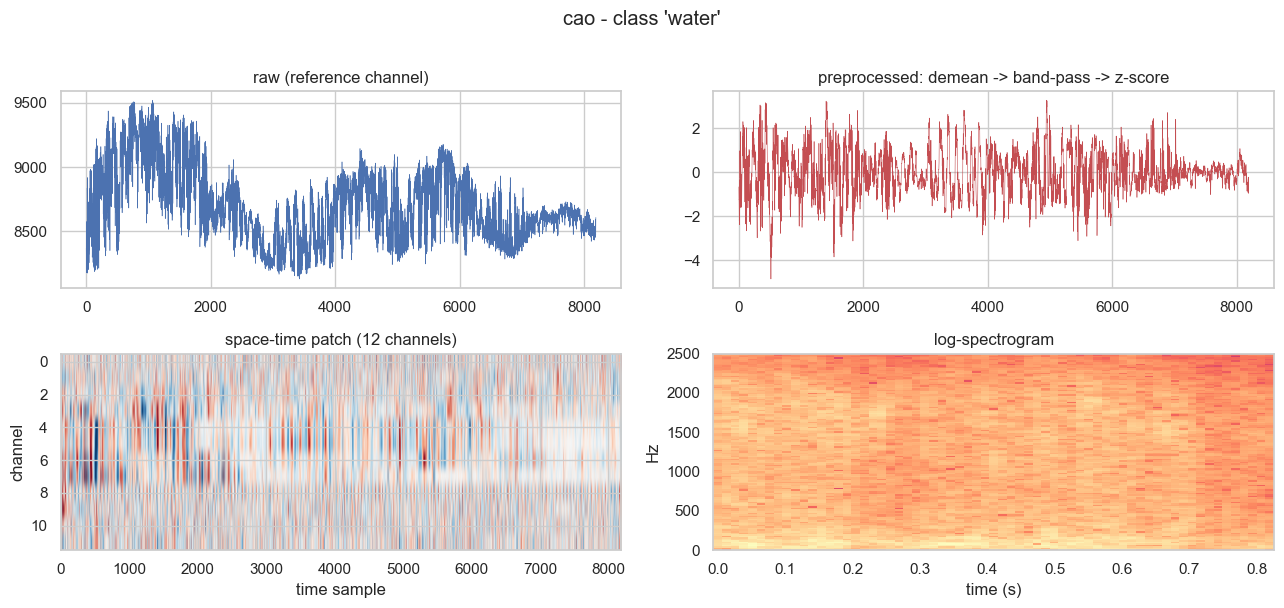

In [4]:
row = manifest.iloc[len(manifest) // 2]

if DATASET == "cao":
    raw = pp.load_cao_window(row.path, spec.win_len)
    fs = spec.fs
    ref = pp.cao_reference_channel(raw)
else:
    with pp.TomasovReader(row.h5_path) as rd:
        raw = rd.read_patch(int(row.t0), int(row.locus), spec.win_len, spec.patch_channels)
        fs = rd.fs
    ref = pp.center_channel_index(spec.patch_channels)

patch = pp.preprocess_patch(raw, fs)
x = patch[ref]
print(f"label={row.label}  raw patch {raw.shape}  reference channel {ref}")

fig, axes = plt.subplots(2, 2, figsize=(13, 6))
axes[0,0].plot(raw[ref], lw=0.4); axes[0,0].set_title("raw (reference channel)")
axes[0,1].plot(x, lw=0.4, color="#C44E52"); axes[0,1].set_title("preprocessed: demean -> band-pass -> z-score")
axes[1,0].imshow(patch, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
axes[1,0].set_title(f"space-time patch ({patch.shape[0]} channels)")
axes[1,0].set_xlabel("time sample"); axes[1,0].set_ylabel("channel")
from scipy.signal import stft
f_, t_, Z = stft(x, fs=fs, nperseg=C.NFFT_STFT, noverlap=C.NFFT_STFT - C.HOP_STFT)
axes[1,1].pcolormesh(t_, f_, np.log10(np.abs(Z) + 1e-12), shading="auto", cmap="magma")
axes[1,1].set_ylim(0, min(2500, fs/2)); axes[1,1].set_title("log-spectrogram")
axes[1,1].set_xlabel("time (s)"); axes[1,1].set_ylabel("Hz")
fig.suptitle(f"{DATASET} - class '{row.label}'", y=1.01)
plt.tight_layout()
plt.savefig(feat_dir / f"example_window_{row.label}.png", dpi=180, bbox_inches="tight")
plt.show()

In [5]:
t0 = time.perf_counter()
feats = EX.extract_window(x, patch, fs)
dt = time.perf_counter() - t0

for d, v in feats.items():
    finite = np.isfinite(v).all()
    print(f"  {d:8s} {v.shape[0]:4d} features  finite={finite}  "
          f"range=[{v.min():.3g}, {v.max():.3g}]")
    assert finite, f"domain '{d}' produced non-finite values"
print(f"\nall four domains: {1000*dt:.1f} ms")

  time      112 features  finite=True  range=[-4.86, 8.19e+03]
  freq       90 features  finite=True  range=[-0.358, 1.25e+07]
  tf        739 features  finite=True  range=[-16.5, 6.34e+03]
  spatial    61 features  finite=True  range=[-1.61, 1.19e+05]

all four domains: 36.4 ms


## 3. Run the extraction

Parallel over chunks. Re-running is safe and cheap: finished shards are detected and
skipped.

In [6]:
t_start = time.perf_counter()
log = EX.run(manifest, DATASET, feat_dir, n_jobs=N_JOBS, verbose=5)
elapsed = time.perf_counter() - t_start

log = log.sort_values("seconds", ascending=False)
display(log.head(20))
print(f"\nchunks: {len(log)}  (skipped {int(log.skipped.sum())})")
print(f"windows extracted: {int(log.n.sum()):,}")
print(f"wall clock: {elapsed/60:.1f} min on {N_JOBS} workers")
if log.n.sum():
    print(f"effective throughput: {log.n.sum()/elapsed:.1f} windows/s")

[Parallel(n_jobs=30)]: Using backend LokyBackend with 30 concurrent workers.


[Parallel(n_jobs=30)]: Done  7 out of 31 | elapsed:   59.8s remaining:  3.4min
[Parallel(n_jobs=30)]: Done 14 out of 31 | elapsed:   60.0s remaining:  1.2min


[Parallel(n_jobs=30)]: Done 21 out of 31 | elapsed:  1.0min remaining:   28.6s


[Parallel(n_jobs=30)]: Done 28 out of 31 | elapsed:  1.0min remaining:    6.4s


[Parallel(n_jobs=30)]: Done 31 out of 31 | elapsed:  1.3min finished


,chunk,n,seconds,skipped
8,chunk_00008,500,54.354947,False
18,chunk_00018,500,54.311655,False
12,chunk_00012,500,54.283819,False
23,chunk_00023,500,54.227561,False
29,chunk_00029,500,54.223221,False
26,chunk_00026,500,54.180376,False
3,chunk_00003,500,54.174958,False
0,chunk_00000,500,54.142147,False
16,chunk_00016,500,54.128953,False
25,chunk_00025,500,54.100997,False



chunks: 31  (skipped 0)
windows extracted: 15,418
wall clock: 1.3 min on 30 workers
effective throughput: 200.0 windows/s


## 4. Assemble the shards

Shards are concatenated in the deterministic chunk order recorded in
`chunk_index.json`. `assemble` verifies row counts, column counts and `sample_id`
uniqueness, so a partially-written shard cannot silently corrupt the feature matrix.

In [7]:
shapes = EX.assemble(feat_dir)
for k, v in shapes.items():
    print(f"  {k:12s} {v if k != 'sample_id' else v.shape}")

ids = np.load(feat_dir / "sample_ids.npy", allow_pickle=True)
print(f"\n{len(ids):,} windows assembled")
missing = len(manifest) - len(ids)
if missing:
    print(f"note: {missing} manifest rows produced no features "
          f"(corrupt or unreadable records)")

  sample_id    (15418,)
  time         (15418, 112)
  freq         (15418, 90)
  tf           (15418, 739)
  spatial      (15418, 61)

15,418 windows assembled


## 5. Quality control on the extracted matrices

Three checks that catch the failure modes that actually happen: non-finite values,
constant (zero-variance) columns, and features whose scale is so extreme they will
dominate distance-based selectors.

In [8]:
qc = []
for d in EX.DOMAIN_ORDER:
    X = np.load(feat_dir / f"X_{d}.npy")
    names = json.load(open(feat_dir / f"features_{d}.json"))
    var = X.var(axis=0)
    qc.append({
        "domain": d, "n_features": X.shape[1], "n_windows": X.shape[0],
        "non_finite": int((~np.isfinite(X)).sum()),
        "constant_cols": int((var == 0).sum()),
        "near_constant": int((var < 1e-12).sum()),
        "max_abs": float(np.abs(X).max()),
        "mem_MB": round(X.nbytes / 1e6, 1),
    })
qc = pd.DataFrame(qc)
qc.loc[len(qc)] = ["TOTAL", qc.n_features.sum(), qc.n_windows.iloc[0],
                   qc.non_finite.sum(), qc.constant_cols.sum(),
                   qc.near_constant.sum(), qc.max_abs.max(), qc.mem_MB.sum()]
display(qc)

assert qc.non_finite.iloc[-1] == 0, "non-finite values in the feature matrices"
print("\nPASS: no non-finite values.")
print("Constant columns are expected and are removed by the variance selector in notebook 05.")

,domain,n_features,n_windows,non_finite,constant_cols,near_constant,max_abs,mem_MB
0,time,112,15418,0,7,9,8.192000e+03,6.9
1,freq,90,15418,0,14,16,3.225850e+07,5.6
2,tf,739,15418,0,0,5,2.854886e+04,45.6
3,spatial,61,15418,0,15,22,1.922224e+05,3.8
4,TOTAL,1002,15418,0,36,52,3.225850e+07,61.9



PASS: no non-finite values.
Constant columns are expected and are removed by the variance selector in notebook 05.


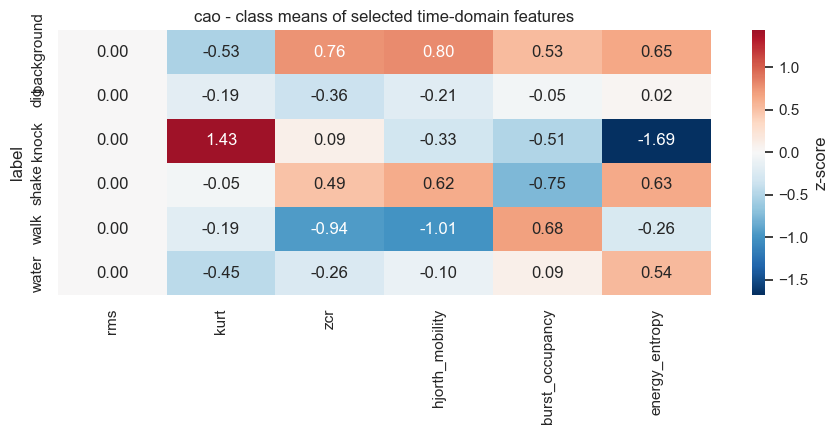

In [9]:
# Per-class separability preview: standardised means of a few time-domain features.
X_time = np.load(feat_dir / "X_time.npy")
names_time = json.load(open(feat_dir / "features_time.json"))
mani = pd.read_parquet(split_dir / "split_manifest.parquet").set_index("sample_id").loc[ids.astype(str)]

probe = ["rms", "kurt", "zcr", "hjorth_mobility", "burst_occupancy", "energy_entropy"]
cols = [names_time.index(p) for p in probe if p in names_time]
Z = (X_time[:, cols] - X_time[:, cols].mean(0)) / (X_time[:, cols].std(0) + 1e-12)
prof = pd.DataFrame(Z, columns=[names_time[c] for c in cols])
prof["label"] = mani.label.to_numpy()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(prof.groupby("label").mean(), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "z-score"})
ax.set_title(f"{DATASET} - class means of selected time-domain features")
plt.tight_layout()
plt.savefig(feat_dir / "class_feature_profile.png", dpi=200)
plt.show()

## 6. Record the extraction cost

Feeds the paper's end-to-end runtime table (offline feature preparation vs online
inference).

In [10]:
timing = {
    "dataset": DATASET,
    "smoke_test": SMOKE_TEST,
    "n_windows": int(len(ids)),
    "n_jobs": N_JOBS,
    "wall_clock_seconds": round(elapsed, 2),
    "windows_per_second": round(len(ids) / elapsed, 2) if elapsed else None,
    "per_domain_ms_per_window": est.set_index("domain")["ms_per_window"].round(3).to_dict(),
    "feature_counts": {d: int(qc.loc[qc.domain == d, "n_features"].iloc[0])
                       for d in EX.DOMAIN_ORDER},
}
(feat_dir / "extraction_timing.json").write_text(json.dumps(timing, indent=2), encoding="utf-8")
qc.to_csv(feat_dir / "feature_qc.csv", index=False)
log.to_csv(feat_dir / "extraction_log.csv", index=False)
print(json.dumps(timing, indent=2))

{
  "dataset": "cao",
  "smoke_test": false,
  "n_windows": 15418,
  "n_jobs": 30,
  "wall_clock_seconds": 77.09,
  "windows_per_second": 200.0,
  "per_domain_ms_per_window": {
    "time": 9.319,
    "freq": 1.184,
    "tf": 19.695,
    "spatial": 6.034,
    "TOTAL": 36.231
  },
  "feature_counts": {
    "time": 112,
    "freq": 90,
    "tf": 739,
    "spatial": 61
  }
}


---
### Checklist before the full run

- [ ] `SMOKE_TEST = True` completed without error for **both** datasets
- [ ] QC shows zero non-finite values
- [ ] Runtime estimate is acceptable
- [ ] Enough free disk: ~1002 x 4 bytes x n_windows (~700 MB for Tomasov)

Then set `SMOKE_TEST = False`, run for `DATASET = "cao"`, then for `DATASET = "tomasov"`.

**Next:** `04_multidomain_fusion.ipynb`.